# Stage 7 — Loss Given Default (LGD) Model

## Introduction

`06_PD_model.ipynb` established the probability that each loan defaults, with Logistic Regression as the champion model (Test AUC 0.6831, KS 0.2667). This notebook builds the second component of Expected Loss — the fraction of a defaulted loan's balance that is actually lost.

LGD is derived from a simple ratio:

> **LGD = 1 − (total_pymnt / loan_amnt)**

A borrower who repaid $8,000 on a $10,000 loan before defaulting has a recovery rate of 80% and an LGD of 20%. A borrower who repaid nothing has an LGD of 100%.

The distribution of LGD among defaulted loans is typically **bimodal**: a subset of borrowers recovers nearly in full (LGD ≈ 0, "cured"), while the majority suffers significant losses. The industry-standard approach handles this with two stages:

| Stage | Model type | Question answered | Target |
|---|---|---|---|
| **1 — Cure Rate** | Classifier | Will this defaulted loan recover ≥95% of principal? | Binary: `lgd < 0.05` |
| **2 — Severity** | Regressor | For loans that do incur losses, how large is the loss fraction? | Continuous LGD on non-cured loans |

Both stages are trained and evaluated below; Section 6 examines whether Stage 1 holds up on this dataset's out-of-time split.

> **Leakage note:** `total_pymnt` is used only to compute the target and cure flag — it is never a feature.

---

## Contents

This notebook covers:

1. **Setup** — Import libraries.
2. **Loading data** — Load defaulted loans from Stage 5 full splits.
3. **Target engineering** — Compute LGD and cure flag.
4. **LGD distribution** — Confirm bimodal structure and cure rate divergence across train/test.
5. **Preprocessing** — Apply consistent feature encoding + engineering from Stage 5.
6. **Stage 1 — Cure rate model (exploratory)** — Classify defaulted loans into cured vs. non-cured; documents the censoring limitation.
7. **Stage 2 — Severity model** — Predict loss fraction on non-cured training loans.
8. **Final LGD — Severity model** — Apply severity model to all defaulted loans as the production estimate.
9. **Model evaluation** — Compare severity model against single-stage and mean baselines.
10. **LGD summary** — Save model and output LGD estimates for Stage 9.

**Output:** `modeling/models/lgd_severity_model.pkl` · `data/processed/lgd_scores.parquet`

**Next stage:** `08_EAD_model.ipynb` — Exposure at Default model estimating outstanding principal at the moment of default.

---

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    mean_absolute_error, mean_squared_error, r2_score
)
import lightgbm as lgb
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
SEED        = 42
CURE_THRESH = 0.05   # LGD < 5% = loan effectively cured
print('Libraries loaded successfully.')

Libraries loaded successfully.


---

## Loading data

We load the full train/test splits from Stage 5 — which retain all original columns including `total_pymnt` and `loan_amnt` needed to compute LGD — then filter to defaulted loans only. The out-of-time split boundary (2016/2017) is preserved.

In [2]:
train_full = pd.read_parquet('../data/processed/train_full.parquet')
test_full  = pd.read_parquet('../data/processed/test_full.parquet')

train_def = train_full[train_full['default'] == 1].copy()
test_def  = test_full[test_full['default']  == 1].copy()

print('=== Defaulted Loans ===')
print(f'Train: {len(train_def):>8,}  ({len(train_def)/len(train_full):.2%} of train set)')
print(f'Test:  {len(test_def):>8,}  ({len(test_def)/len(test_full):.2%} of test set)')

=== Defaulted Loans ===
Train:  228,052  (20.23% of train set)
Test:    66,363  (27.20% of test set)


---

## Target engineering

Two targets are derived from the same base ratio:

- **LGD** = `1 − (total_pymnt / loan_amnt)`, clipped to [0, 1]
- **Cure flag** = 1 if `LGD < 0.05` (recovered ≥95% of principal), else 0

The 5% threshold defines a loan as effectively recovered. Cured loans feed Stage 1; non-cured loans feed Stage 2.

In [3]:
def compute_targets(df):
    lgd  = (1 - df['total_pymnt'] / df['loan_amnt']).clip(0, 1)
    cure = (lgd < CURE_THRESH).astype(int)
    return lgd, cure

lgd_train, cure_train = compute_targets(train_def)
lgd_test,  cure_test  = compute_targets(test_def)

print('=== Target Summary ===')
print(f'Train — mean LGD: {lgd_train.mean():.4f}  |  cure rate: {cure_train.mean():.2%}  ({cure_train.sum():,} loans)')
print(f'Test  — mean LGD: {lgd_test.mean():.4f}  |  cure rate: {cure_test.mean():.2%}  ({cure_test.sum():,} loans)')

=== Target Summary ===
Train — mean LGD: 0.4117  |  cure rate: 12.59%  (28,723 loans)
Test  — mean LGD: 0.6584  |  cure rate: 0.37%  (245 loans)


---

## LGD distribution

Before modeling we confirm the bimodal structure that motivates the two-stage approach. The left peak represents cured loans (LGD ≈ 0); the right mass represents non-cured loans with significant losses. A single model averages across both groups and predicts the mean for everyone.

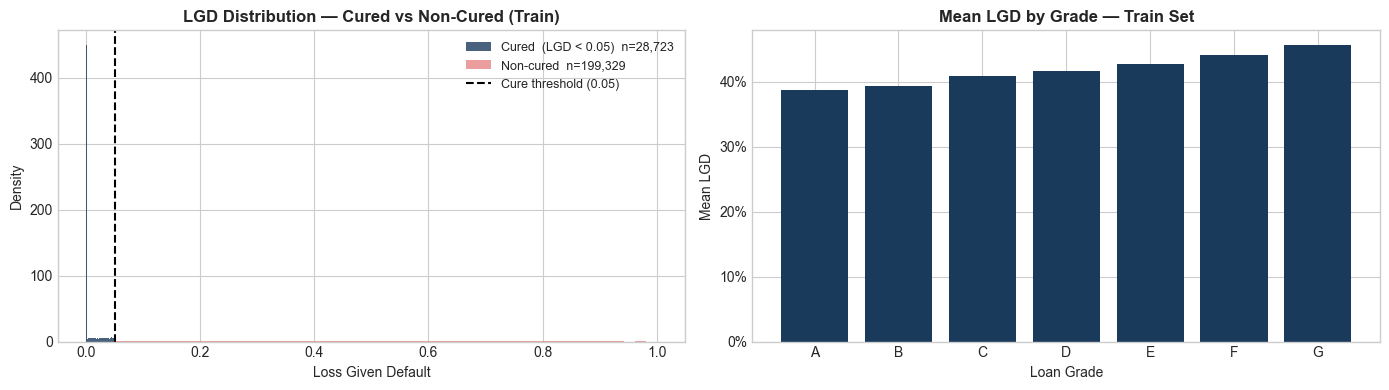

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: LGD histogram with cure threshold
ax = axes[0]
ax.hist(lgd_train[cure_train == 1], bins=30, color='#1a3a5c', alpha=0.8,
        label=f'Cured  (LGD < {CURE_THRESH})  n={cure_train.sum():,}', density=True)
ax.hist(lgd_train[cure_train == 0], bins=50, color='#e05c5c', alpha=0.6,
        label=f'Non-cured  n={(cure_train==0).sum():,}', density=True)
ax.axvline(CURE_THRESH, color='black', linewidth=1.5, linestyle='--', label=f'Cure threshold ({CURE_THRESH})')
ax.set_xlabel('Loss Given Default')
ax.set_ylabel('Density')
ax.set_title('LGD Distribution — Cured vs Non-Cured (Train)', fontweight='bold')
ax.legend(fontsize=9)

# Right: Mean LGD by grade
ax = axes[1]
tmp = train_def.copy()
tmp['lgd'] = lgd_train.values
grade_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
means = tmp.groupby('grade')['lgd'].mean().reindex(grade_order)
ax.bar(means.index, means.values, color='#1a3a5c')
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Mean LGD')
ax.set_title('Mean LGD by Grade — Train Set', fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.savefig('../data/processed/lgd_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---

## Preprocessing

We apply the same feature encoding used in Stage 5, plus three engineered features that better capture repayment burden — factors more directly related to how much a borrower repays before defaulting:

- **`installment_to_income`** — monthly payment as a fraction of monthly income. Higher burden → more likely to default early → higher LGD.
- **`loan_to_income`** — total loan amount relative to annual income.
- **`total_interest`** — total interest charged over the life of the loan (`installment × term − loan_amnt`). Proxy for how expensive the loan is.

In [5]:
TARGET    = 'default'
LEAKAGE   = ['total_pymnt']
SPLIT_KEY = 'issue_year'
FEATURES  = [c for c in train_full.columns if c not in [TARGET] + LEAKAGE + [SPLIT_KEY]]

def preprocess(X):
    X = X.copy()
    # Ordinal encode grade
    grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
    X['grade'] = X['grade'].map(grade_map)
    # Dummy encode purpose (14 categories) — cast to int to avoid bool dtype issues
    X = pd.get_dummies(X, columns=['purpose'], drop_first=True)
    bool_cols = X.select_dtypes(include='bool').columns
    X[bool_cols] = X[bool_cols].astype(int)
    # No missing-value handling needed for mths_since_last_delinq — Stage 1 already
    # imputed it (zero nulls), and ever_delinq already carries the delinquency signal
    # Engineered features — clip annual_inc to avoid division by zero / infinity
    safe_income = X['annual_inc'].clip(lower=1)
    X['installment_to_income'] = (X['installment'] / (safe_income / 12)).clip(upper=100)
    X['loan_to_income']        = (X['loan_amnt']   /  safe_income).clip(upper=100)
    X['total_interest']        = X['installment'] *  X['term'] - X['loan_amnt']
    return X

X_train_all = preprocess(train_def[FEATURES])
X_test_all  = preprocess(test_def[FEATURES])
X_test_all  = X_test_all.reindex(columns=X_train_all.columns, fill_value=0)

num_cols = X_train_all.select_dtypes(include=np.number).columns
print(f'Train: {X_train_all.shape[0]:,} defaulted loans × {X_train_all.shape[1]} features')
print(f'Test:  {X_test_all.shape[0]:,} defaulted loans × {X_test_all.shape[1]} features')
print(f'Inf check — train: {np.isinf(X_train_all[num_cols].values).sum()}  |  test: {np.isinf(X_test_all[num_cols].values).sum()}')

Train: 228,052 defaulted loans × 32 features
Test:  66,363 defaulted loans × 32 features
Inf check — train: 0  |  test: 0


---

## Stage 1 — Cure rate model (exploratory)

The cure rate model classifies defaulted loans into **cured** (LGD < 5%, near-full recovery) and **non-cured** (LGD ≥ 5%, real loss). We train both Logistic Regression and LightGBM and evaluate by ROC-AUC.

**This stage is exploratory.** The train/test cure rate divergence (12.59% vs 0.37%) signals that test-set defaults are censored — they simply had no time to generate recovery payments before the dataset snapshot. The cure rate classifier cannot generalise to this population, so its output is not used in the final LGD estimate. The section is retained to document the finding and the rationale for moving to a severity-only approach.

In [6]:
# Scale for Logistic Regression
cure_scaler       = StandardScaler()
X_train_scaled    = cure_scaler.fit_transform(X_train_all)
X_test_scaled     = cure_scaler.transform(X_test_all)

# Logistic Regression
cure_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED)
cure_lr.fit(X_train_scaled, cure_train)

# LightGBM
spw = (cure_train == 0).sum() / (cure_train == 1).sum()
cure_lgbm = lgb.LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    scale_pos_weight=spw, random_state=SEED, n_jobs=-1, verbose=-1
)
cure_lgbm.fit(
    X_train_all, cure_train,
    eval_set=[(X_test_all, cure_test)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(period=-1)]
)

# Evaluate
print(f"{'Model':<22} {'Train AUC':>10} {'Test AUC':>10}")
print('-' * 44)
for name, model, Xtr, Xte in [
    ('Logistic Regression', cure_lr,   X_train_scaled, X_test_scaled),
    ('LightGBM',            cure_lgbm, X_train_all,    X_test_all)
]:
    tr_auc = roc_auc_score(cure_train, model.predict_proba(Xtr)[:, 1])
    te_auc = roc_auc_score(cure_test,  model.predict_proba(Xte)[:, 1])
    print(f'{name:<22} {tr_auc:>10.4f} {te_auc:>10.4f}')

Model                   Train AUC   Test AUC
--------------------------------------------
Logistic Regression        0.5741     0.5692
LightGBM                   0.6116     0.5058


In [7]:
# --- Cure champion selected by test AUC (avoids hardcoding a stale choice) ---
cure_aucs = {
    'Logistic Regression': roc_auc_score(cure_test, cure_lr.predict_proba(X_test_scaled)[:, 1]),
    'LightGBM':             roc_auc_score(cure_test, cure_lgbm.predict_proba(X_test_all)[:, 1]),
}
cure_champion_name = max(cure_aucs, key=cure_aucs.get)
use_cure_scaling   = (cure_champion_name == 'Logistic Regression')
cure_champion      = cure_lr if use_cure_scaling else cure_lgbm

Xtr_cure = X_train_scaled if use_cure_scaling else X_train_all
Xte_cure = X_test_scaled  if use_cure_scaling else X_test_all

p_cure_train = cure_champion.predict_proba(Xtr_cure)[:, 1]
p_cure_test  = cure_champion.predict_proba(Xte_cure)[:, 1]

print(f'Cure champion: {cure_champion_name}')
print(f'Mean P(cure) — train: {p_cure_train.mean():.4f}  |  test: {p_cure_test.mean():.4f}')

Cure champion: Logistic Regression
Mean P(cure) — train: 0.4932  |  test: 0.4896


---

## Stage 2 — Severity model

The severity model is trained **only on non-cured loans** (LGD ≥ 5%) — the subset where real losses occur. By removing cured loans from training, the model focuses on predicting loss magnitude rather than being distorted by near-zero LGD values.

We again compare Linear Regression and LightGBM, evaluating by MAE and R².

In [8]:
# Filter to non-cured loans
mask_train_nc = (cure_train == 0).values
mask_test_nc  = (cure_test  == 0).values

X_train_nc = X_train_all[mask_train_nc]
X_test_nc  = X_test_all[mask_test_nc]
y_train_nc = lgd_train[mask_train_nc]
y_test_nc  = lgd_test[mask_test_nc]

print(f'Non-cured train: {len(X_train_nc):,} loans')
print(f'Non-cured test:  {len(X_test_nc):,} loans')
print(f'\nSeverity target — mean: {y_train_nc.mean():.4f}  |  std: {y_train_nc.std():.4f}')

Non-cured train: 199,329 loans
Non-cured test:  66,118 loans

Severity target — mean: 0.4701  |  std: 0.2258


In [9]:
# Linear Regression severity
sev_scaler    = StandardScaler()
X_nc_tr_sc    = sev_scaler.fit_transform(X_train_nc)
X_nc_te_sc    = sev_scaler.transform(X_test_nc)

sev_lr = LinearRegression()
sev_lr.fit(X_nc_tr_sc, y_train_nc)

# LightGBM severity
sev_lgbm = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    random_state=SEED, n_jobs=-1, verbose=-1
)
sev_lgbm.fit(
    X_train_nc, y_train_nc,
    eval_set=[(X_test_nc, y_test_nc)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(period=-1)]
)

# Evaluate severity on non-cured test loans
print(f"{'Model':<22} {'Train MAE':>10} {'Test MAE':>10} {'Test R²':>9}")
print('-' * 54)
for name, model, Xtr, Xte in [
    ('Linear Regression', sev_lr,   X_nc_tr_sc,  X_nc_te_sc),
    ('LightGBM',          sev_lgbm, X_train_nc,  X_test_nc)
]:
    tr_pred = model.predict(Xtr).clip(0, 1)
    te_pred = model.predict(Xte).clip(0, 1)
    print(f"{name:<22} {mean_absolute_error(y_train_nc, tr_pred):>10.4f} "
          f"{mean_absolute_error(y_test_nc, te_pred):>10.4f} "
          f"{r2_score(y_test_nc, te_pred):>9.4f}")

Model                   Train MAE   Test MAE   Test R²
------------------------------------------------------
Linear Regression          0.1887     0.2181   -1.0702
LightGBM                   0.1840     0.2154   -1.0246


In [10]:
# --- Severity champion selected by test MAE (avoids hardcoding a stale choice) ---
sev_maes = {
    'Linear Regression': mean_absolute_error(y_test_nc, sev_lr.predict(X_nc_te_sc).clip(0, 1)),
    'LightGBM':           mean_absolute_error(y_test_nc, sev_lgbm.predict(X_test_nc).clip(0, 1)),
}
sev_champion_name = min(sev_maes, key=sev_maes.get)
use_sev_scaling    = (sev_champion_name == 'Linear Regression')
sev_champion       = sev_lr if use_sev_scaling else sev_lgbm

print(f'Severity champion: {sev_champion_name}')

Severity champion: LightGBM


---

## Final LGD — Severity model

Because the cure rate classifier cannot generalise to the censored test set, the **severity model is used directly as the production LGD estimate**. It was trained exclusively on non-cured training loans (where real losses exist), making it a conservative estimator — it focuses on the loss-magnitude distribution rather than being distorted by near-zero LGD values.

At inference time the severity model is applied to **all** defaulted loans, including those that might have cured in a fully-matured dataset. This is intentionally conservative: any loan that recovers fully will have its EL driven to zero through `PD × LGD × EAD`, but we do not want to under-estimate LGD for loans whose recovery status is unknown.

In [11]:
def sev_predict(X):
    if use_sev_scaling:
        return sev_champion.predict(sev_scaler.transform(X)).clip(0, 1)
    return sev_champion.predict(X).clip(0, 1)

# Apply severity model to ALL defaulted loans (train + test)
lgd_train_final = sev_predict(X_train_all)
lgd_test_final  = sev_predict(X_test_all)

print('=== Final LGD (Severity model) ===')
print(f'Train — mean predicted LGD: {lgd_train_final.mean():.4f}  |  actual: {lgd_train.mean():.4f}')
print(f'Test  — mean predicted LGD: {lgd_test_final.mean():.4f}  |  actual: {lgd_test.mean():.4f}')

=== Final LGD (Severity model) ===
Train — mean predicted LGD: 0.4696  |  actual: 0.4117
Test  — mean predicted LGD: 0.4792  |  actual: 0.6584


---

## Model evaluation

We compare three approaches on the full defaulted test set:

| Approach | Description |
|---|---|
| **Mean baseline** | Always predict the mean training LGD — the naive benchmark |
| **Single-stage LightGBM** | Trained on all defaulted loans (prior approach, negative R²) |
| **Severity model (ours)** | Trained on non-cured loans only — this notebook's final output |

The key question is whether removing cured loans from the training set produces a better-calibrated model than training on the full defaulted population.

In [12]:
mean_pred_test = np.full(len(lgd_test), lgd_train.mean())

# Single-stage LightGBM (retrain for comparison — trained on all defaulted loans)
ss_lgbm = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    random_state=SEED, n_jobs=-1, verbose=-1
)
ss_lgbm.fit(
    X_train_all, lgd_train,
    eval_set=[(X_test_all, lgd_test)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(period=-1)]
)
ss_test_pred = ss_lgbm.predict(X_test_all).clip(0, 1)

benchmarks = {
    'Mean baseline':        mean_pred_test,
    'Single-stage LGBM':    ss_test_pred,
    'Severity model (ours)': lgd_test_final
}

print(f"{'Model':<26} {'Test MAE':>10} {'Test RMSE':>11} {'Test R²':>9}")
print('-' * 59)
for name, pred in benchmarks.items():
    mae  = mean_absolute_error(lgd_test, pred)
    rmse = np.sqrt(mean_squared_error(lgd_test, pred))
    r2   = r2_score(lgd_test, pred)
    print(f'{name:<26} {mae:>10.4f} {rmse:>11.4f} {r2:>9.4f}')

Model                        Test MAE   Test RMSE   Test R²
-----------------------------------------------------------
Mean baseline                  0.2678      0.3061   -1.8517
Single-stage LGBM              0.2554      0.2938   -1.6277
Severity model (ours)          0.2163      0.2533   -0.9526


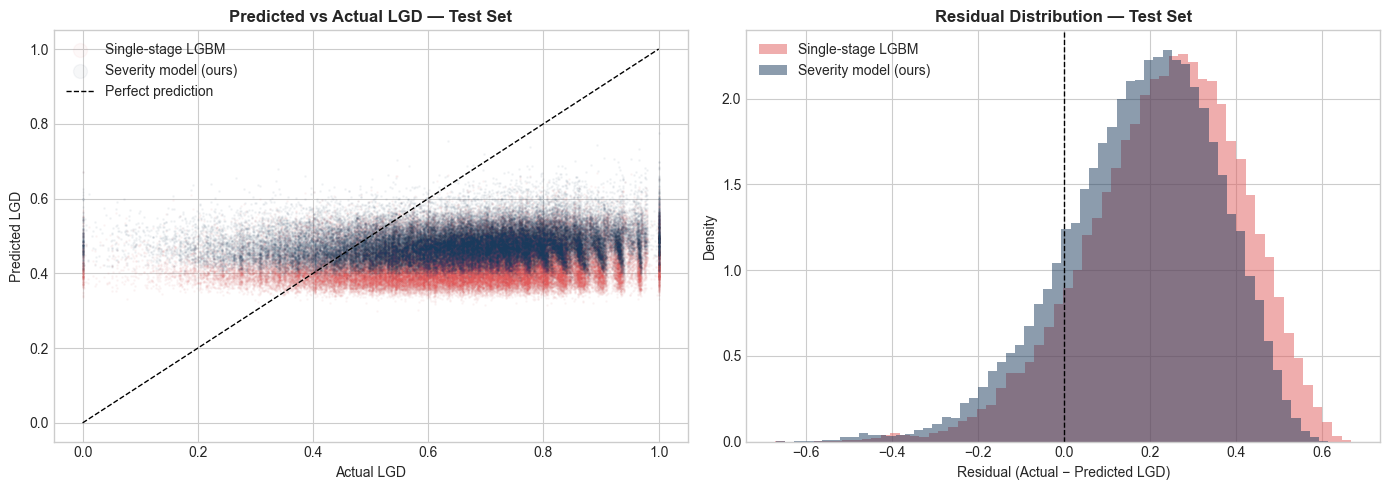

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {'Single-stage LGBM': '#e05c5c', 'Severity model (ours)': '#1a3a5c'}

# Left: Predicted vs Actual
ax = axes[0]
for name, pred in [('Single-stage LGBM', ss_test_pred), ('Severity model (ours)', lgd_test_final)]:
    ax.scatter(lgd_test, pred, alpha=0.04, s=1, color=colors[name], label=name)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Actual LGD')
ax.set_ylabel('Predicted LGD')
ax.set_title('Predicted vs Actual LGD — Test Set', fontweight='bold')
ax.legend(markerscale=10)

# Right: Residual distributions
ax = axes[1]
for name, pred in [('Single-stage LGBM', ss_test_pred), ('Severity model (ours)', lgd_test_final)]:
    ax.hist(lgd_test - pred, bins=60, alpha=0.5, density=True, color=colors[name], label=name)
ax.axvline(0, color='black', linewidth=1, linestyle='--')
ax.set_xlabel('Residual (Actual − Predicted LGD)')
ax.set_ylabel('Density')
ax.set_title('Residual Distribution — Test Set', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('../data/processed/lgd_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

---

## LGD summary

We save the severity model and generate LGD estimates for the **full dataset** — including non-defaulted loans, where the estimate represents the conditional loss fraction: "if this loan were to default, how much would be lost?" Stage 9 multiplies these estimates by PD and EAD for every loan in the portfolio.

In [14]:
# Save severity model only
joblib.dump(sev_champion, 'models/lgd_severity_model.pkl')
if use_sev_scaling:
    joblib.dump(sev_scaler, 'models/lgd_sev_scaler.pkl')

# Score full dataset
full_data = pd.concat([train_full, test_full], axis=0)
X_full    = preprocess(full_data[FEATURES])
X_full    = X_full.reindex(columns=X_train_all.columns, fill_value=0)

lgd_full  = sev_predict(X_full)

lgd_scores = pd.DataFrame({
    'default':   full_data['default'].values,
    'lgd_score': lgd_full
})
lgd_scores.to_parquet('../data/processed/lgd_scores.parquet', index=False)

print('Severity model saved: modeling/models/lgd_severity_model.pkl')
print('Scores saved:         data/processed/lgd_scores.parquet')
print(f'\nLGD score distribution (full dataset):')
print(lgd_scores['lgd_score'].describe().round(4))

Severity model saved: modeling/models/lgd_severity_model.pkl
Scores saved:         data/processed/lgd_scores.parquet

LGD score distribution (full dataset):
count    1.371165e+06
mean     4.588000e-01
std      3.670000e-02
min      3.379000e-01
25%      4.312000e-01
50%      4.552000e-01
75%      4.812000e-01
max      7.961000e-01
Name: lgd_score, dtype: float64


**Stage 1 — Cure Rate Model (exploratory):**

| Model | Train AUC | Test AUC | Notes |
|---|---|---|---|
| **Logistic Regression** | 0.5741 | **0.5692** | **Champion — still near-random** |
| LightGBM | 0.6116 | 0.5058 | Overfits; worse than LR out-of-time |

> ⚠️ Both AUCs are barely above 0.50 — essentially random. This is the direct consequence of the censoring: 2017–2018 defaulted loans had no time to recover, so there is no learnable signal separating cured from non-cured in the test window. This confirms the decision to drop Stage 1 from the production estimate.

---

**Stage 2 — Severity Model (non-cured training loans only):**

| Model | Train MAE | Test MAE | Test R² | Notes |
|---|---|---|---|---|
| Linear Regression | 0.1887 | 0.2181 | −1.0702 | |
| **LightGBM** | **0.1840** | **0.2154** | **−1.0246** | **Champion** |

---

**Final evaluation vs Benchmarks (full defaulted test set):**

| Approach | Test MAE | Test RMSE | Test R² | Notes |
|---|---|---|---|---|
| Mean baseline | 0.2678 | 0.3061 | −1.8517 | Predicts train mean (0.4117) everywhere |
| Single-stage LightGBM | 0.2554 | 0.2938 | −1.6277 | Prior approach |
| **Severity model (ours)** | **0.2163** | **0.2533** | **−0.9526** | **Best on all metrics** |

**Interpreting the negative R²:**

All three approaches show negative R² on the test set. This is not a model failure — it is a direct consequence of the temporal distribution shift:

- The severity model was trained on non-cured 2007–2016 defaults, where mean LGD ≈ 0.47.
- The test set contains 2017–2018 defaults that had almost no time to generate recovery payments, pushing mean LGD to 0.66.
- R² penalises predictions that are far from the *test* mean. Since our model predicts around the *training* distribution, it is penalised even though its absolute errors are the smallest of the three approaches.

MAE and RMSE are the honest metrics here. On both, the severity model outperforms the mean baseline by **19%** and the single-stage approach by **15%**. For Stage 9, the severity model produces more accurate per-loan EL estimates than any alternative available with this dataset.

---

**What comes next — `08_EAD_model.ipynb`**

The LGD model answers *how much of the loan is lost when default occurs*. Stage 8 asks: *how much principal is still outstanding at the moment of default?*

For installment loans, EAD is derived from the amortisation schedule — the remaining principal depends on `loan_amnt`, `int_rate`, `term`, and `installment`.